# Benchmark: identifying drivers among proxies and noise

An analyst with thirty candidate predictors and no prior about which matter
wants two things from a model: the set of predictors that drive the response,
and the shape of each effect. This study measures how well each method
delivers both when some non-drivers are strongly correlated with drivers
(proxies) and the rest are correlated noise.

The data have 30 predictors, each uniform on $(-1, 1)$ through a Gaussian
copula (normal scores mapped to the uniform scale, so the correlations below
are set on the normal scale):

* six **drivers** with different shapes, $f_1(x) = x$ (line),
  $f_2(x) = \sin \pi x$ (sine), $f_3(x) = 1.5(x^2 - 1/3)$ (parabola),
  $f_4(x) = 0.8\,[x > 0]$ (step), $f_5(x) = 1.5\exp(-10x^2)$ (bump) and
  $f_6(x) = 0.5x$ (a weak line), correlated 0.2 with each other;
* three **proxies** `p1`, `p2`, `p3`, correlated 0.8 with `x1`, `x2` and `x3`
  and without effect;
* 21 **noise** predictors `z1` to `z21` without effect, correlated among
  themselves (0.5 between neighbours, decaying with distance) and independent
  of the drivers.

The response is $y = \sum_{j=1}^6 f_j(x_j) + \varepsilon$ with standard normal
noise (tasks `gauss500` and `gauss2000`, 500 and 2,000 training rows), or a
Bernoulli outcome whose log-odds are $\sum_j f_j(x_j)$ (task `binary1000`,
1,000 rows).

Every method receives all 30 columns and its default specification, as an
analyst without knowledge of the generating process would fit them: mboostrs
starts from `y ~ .`, which fits each numeric column as a default P-spline
`bbs(x, df=4)`, or from `autospec`, which chooses the specification from the
data; mgcv gets `s(x)` for every column with `select=TRUE`. The process is
used only at the end, to grade each result.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the set of predictors each method reports as having an effect, and the shape it gives each predictor |
| **Observed response** | simulated: Gaussian (sd 1) or Bernoulli |
| **Estimand** | true-positive rate over the six drivers; false discoveries (proxies and noise in the reported set); whether the reported set is exactly the six drivers; importance-ranking AUC; structure error, the root mean squared difference between each predictor's centred partial dependence and its true centred effect (zero for non-drivers), over all 30 predictors; RMSE of the predicted signal on 3,000 test rows |
| **Units** | counts and proportions; link-scale units (response units, or log-odds for the binary task) |
| **Sampling unit** | one row; 500, 2,000 or 1,000 training rows and 3,000 test rows per seed |
| **Dependence** | independent rows; correlated predictors as described |
| **Split / resampling unit** | a fresh test sample from the same design |
| **Tuning** | mboostrs: `tune_mstop` (5-fold cross-validation); `deselect` threshold 0.01; `stabsel` with `PFER=1`, `cutoff=0.75`; `autospec(budget=200)`; mgcv: REML with `select=TRUE`, a term reported at p < 0.05; glmnet: 5-fold CV, `lambda.1se`; gamsel: 5-fold CV, `index.1se`; knockoffs: second-order Gaussian knockoffs, target FDR 0.1; Boruta: ranger forests, 200 rounds, confirmed predictors only; LightGBM: early stopping on a 20% validation split over 4, 15 and 31 leaves; EBM: defaults |
| **Uncertainty** | mean and standard error over 20 seeds |
| **Claim type** | methodological: behaviour of the methods on a design with known structure |
:::

All existing autospec rows are refreshed under native pre-exploration in
`bench_drivers_preexploration.json`, using
`python benches/refresh_autospec.py --studies drivers`. Retained competitor
and non-autospec rows keep their original values, timestamps and build
fingerprints. The artifact records both measurement vintages. Wall times
are descriptive workflow costs, not same-build speed ratios.

## The methods and what each reports

The methods differ in what they return. Selection methods return a set;
ranking methods return an importance score per predictor; additive models
also return a shape for every predictor, which the study scores by partial
dependence (the mean prediction over 150 training rows with one predictor set
to each of 21 grid values).

| Method | Selected set | Importance | Shapes |
|---|---|---|---|
| mboostrs `y ~ .`, cross-validated `mstop` | learners with any risk reduction | risk reduction (`varimp`) | yes |
| mboostrs `deselect` | learners with at least 1% of the risk reduction, refitted | risk reduction | yes |
| mboostrs `deselect` + REML refit | as `deselect`, then `gam_refit` | risk reduction | yes |
| mboostrs `probe` | learners selected before the first permuted shadow column | risk reduction | no |
| mboostrs `stabsel` | selection frequency ≥ 0.75 with `PFER=1` (at most 4 learners per subsample) | selection frequency | no |
| mboostrs `stabsel (q=8)` | selection frequency ≥ 0.9 with 8 learners per subsample | selection frequency | no |
| mboostrs `autospec` | the terms of the recommended specification, which drops terms under 1% of the risk reduction | risk reduction | yes |
| mboostrs `autospec` + REML refit | `rec.fit(data, refit="reml")` | none | yes |
| mboostrs `autospec` (deselect 2.5%) | as `autospec`, asking for a sparser set with `deselect=0.025` | risk reduction | yes |
| mgcv `select=TRUE` | smooth terms with p < 0.05 | $-\log_{10} p$ | yes |
| lasso (glmnet) | non-zero coefficients at `lambda.1se` | absolute coefficient | linear |
| gamsel (sparse additive model) | columns with a non-zero linear or spline part at `index.1se` | size of the fitted term | yes |
| knockoffs (lasso or forest statistic) | knockoff+ selection at FDR 0.1 (offset 1, the default) | knockoff statistic | no |
| knockoffs, offset 0 | knockoff selection at a modified FDR of 0.1 | knockoff statistic | no |
| Boruta | confirmed against shadow features | mean importance | no |
| EBM | none | term importance, with each pair term's importance split between its two columns | yes |
| LightGBM | none | mean absolute SHAP value | yes |

The code below reads the results that `benches/bench_drivers.py` wrote
(`python benches/bench_drivers.py --out docs/book/cases/bench_drivers_preexploration.json`
reproduces them in about two hours on ten cores) and shows one record.

In [1]:
import json
from pathlib import Path

import altair as alt
import polars as pl

bench = json.loads(Path("bench_drivers_preexploration.json").read_text())
records = [r for r in bench["results"] if "error" not in r and "failure" not in r]
failed = [r for r in bench["results"] if "error" in r or "failure" in r]

# One record: the fields every method reports, before aggregation.
example = next(r for r in records if r["method"] == "mboostrs deselect + REML refit")
{k: (round(v, 3) if isinstance(v, float) else v)
 for k, v in example.items() if k != "effect_rmse"}

{'task': 'gauss500',
 'method': 'mboostrs deselect + REML refit',
 'seed': 0,
 'seconds': 1.746,
 'auc_drivers': 1.0,
 'auc_proxies': 1.0,
 'selected': ['x1', 'x2', 'x3', 'x4', 'x5', 'x6'],
 'tpr': 1.0,
 'false_share': 0.0,
 'n_false': 0,
 'proxies_selected': 0,
 'exact': True,
 'signal_rmse': 0.246,
 'structure_error': 0.042,
 'driver_effect_rmse': 0.082,
 'spurious_effect_rmse': 0.0,
 '_status': 'success',
 '_identity': {'fingerprint': '087c6bee58caa22498994918033716fe6a41f2ffa27d0e67a97e434c794ab5c6',
  'components': {'runner_modules': ['_jobs',
    'bench_drivers',
    'benchmark_contract'],
   'runner_hash': '01919a0bef31cd2df6447c71bd99aff25c359d715495936398e1ea2863c62131',
   'environment': {'python': '3.12.11',
    'executable': '/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/a53516a1-e413-4454-80f2-6280ed9497f4/scratchpad/benchenv3/bin/python',
    'platform': 'macOS-26.3-arm64-arm-64bit',
    'machine': 'arm64',
    'packages': {'numpy': '2.4.6',
     'polars

`tpr` is the share of the six drivers in `selected`; `n_false` counts
proxies and noise predictors in it, `proxies_selected` the proxies alone;
`exact` says whether `selected` is exactly the six drivers. `auc_drivers` is
the probability that a random driver outranks a random non-driver by the
method's importance score, and `auc_proxies` the same against the three
proxies only. `structure_error` combines the shape errors of all 30
predictors; `driver_effect_rmse` averages the six drivers' errors and
`spurious_effect_rmse` measures the effect given to the 24 non-drivers.

In [2]:
SCORES = ["tpr", "n_false", "proxies_selected", "exact", "auc_drivers",
          "auc_proxies", "structure_error", "driver_effect_rmse",
          "spurious_effect_rmse", "signal_rmse", "seconds"]
flat = pl.DataFrame([{k: r.get(k) for k in ["task", "method", "seed"] + SCORES}
                     for r in records], infer_schema_length=None)
flat = flat.with_columns(pl.col("exact").cast(pl.Float64))

# Mean and standard error over seeds, per task and method.
aggs = [pl.len().alias("fits")]
for column in SCORES:
    aggs += [pl.col(column).cast(pl.Float64).mean().alias(column),
             (pl.col(column).cast(pl.Float64).std() / pl.len().sqrt()).alias(f"{column} se")]
table = flat.group_by("task", "method").agg(aggs)


def value(task, method, column):
    row = table.filter((pl.col("task") == task) & (pl.col("method") == method))
    return float(row[column][0])


f"{len(records)} fits, {len(failed)} failed"


'1140 fits, 0 failed'

In [3]:
from bench_tables import table as annotated

headline = table.filter(pl.col("task") == "gauss2000").select(
    "method", "signal_rmse", "signal_rmse se", "structure_error", "tpr", "n_false", "seconds")
annotated(headline.sort("signal_rmse"), title="Prediction, effects and selection at 2,000 Gaussian rows",
    subtitle="Every measured method; means over 20 seeds; lower errors are better",
    labels={"signal_rmse": "Signal RMSE", "signal_rmse se": "SE", "structure_error": "Effect error",
            "tpr": "Drivers ↑", "n_false": "False ↓", "seconds": "Seconds"},
    spanners={"Response units": ["signal_rmse", "signal_rmse se", "structure_error"]},
    better={"signal_rmse": "min", "structure_error": "min", "tpr": "max", "n_false": "min"},
    notes=["Signal RMSE compares predictions with the true mean; SE is Monte Carlo error over seeds.",
           "Effect error summarizes all 30 partial-effect curves. Drivers is the fraction of six true drivers retained.",
           "A missing selected-set metric means the method supplies a ranking instead. Timings retain their measurement dates.",
           f"Artifact: {len(records)} successful fits and {len(failed)} failures across all tasks."])

GT(_tbl_data=shape: (19, 7)
┌────────────────┬─────────────┬────────────────┬────────────────┬──────────┬─────────┬────────────┐
│ method         ┆ signal_rmse ┆ signal_rmse se ┆ structure_erro ┆ tpr      ┆ n_false ┆ seconds    │
│ ---            ┆ ---         ┆ ---            ┆ r              ┆ ---      ┆ ---     ┆ ---        │
│ str            ┆ f64         ┆ f64            ┆ ---            ┆ f64      ┆ f64     ┆ f64        │
│                ┆             ┆                ┆ f64            ┆          ┆         ┆            │
╞════════════════╪═════════════╪════════════════╪════════════════╪══════════╪═════════╪════════════╡
│ knockoff       ┆ null        ┆ null           ┆ null           ┆ 1.0      ┆ 1.35    ┆ 13.206619  │
│ offset 0       ┆             ┆                ┆                ┆          ┆         ┆            │
│ (forest)       ┆             ┆                ┆                ┆          ┆         ┆            │
│ mboostrs probe ┆ null        ┆ null           ┆ null           ┆ 0.691667 ┆ 0.75    ┆ 4.986167   │
│ Boruta         ┆ null        ┆ null           ┆ null           ┆ 1.0      ┆ 3.1     ┆ 276.665487 │
│ knockoff       ┆ null        ┆ null           ┆ null           ┆ 0.05     ┆ 0.25    ┆ 18.974748  │
│ (forest)       ┆             ┆                ┆                ┆          ┆         ┆            │
│ knockoff       ┆ null        ┆ null           ┆ null           ┆ 0.675    ┆ 1.45    ┆ 12.399485  │
│ offset 0       ┆             ┆                ┆                ┆          ┆         ┆            │
│ (lasso)        ┆             ┆                ┆                ┆          ┆         ┆            │
│ …              ┆ …           ┆ …              ┆ …              ┆ …        ┆ …       ┆ …          │
│ mboostrs (CV)  ┆ 0.21219     ┆ 0.002358       ┆ 0.040326       ┆ 1.0      ┆ 13.75   ┆ 5.29294    │
│ gamsel (sparse ┆ 0.307062    ┆ 0.003943       ┆ 0.056987       ┆ 1.0      ┆ 12.15   ┆ 26.413588  │
│ GAM 1se)       ┆             ┆                ┆                ┆          ┆         ┆            │
│ LightGBM +     ┆ 0.318152    ┆ 0.002893       ┆ 0.054109       ┆ null     ┆ null    ┆ 3.101075   │
│ SHAP           ┆             ┆                ┆                ┆          ┆         ┆            │
│ EBM            ┆ 0.358258    ┆ 0.005251       ┆ 0.063872       ┆ null     ┆ null    ┆ 181.487173 │
│ lasso (glmnet  ┆ 0.860867    ┆ 0.004238       ┆ 0.156377       ┆ 0.675    ┆ 0.1     ┆ 6.09318    │
│ 1se)           ┆             ┆                ┆                ┆          ┆         ┆            │
└────────────────┴─────────────┴────────────────┴────────────────┴──────────┴─────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x112623560>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='signal_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='Signal RMSE', column_align='right', column_width=None), ColInfo(var='signal_rmse se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None), ColInfo(var='structure_error', type=<ColInfoTypeEnum.default: 1>, column_label='Effect error', column_align='right', column_width=None), ColInfo(var='tpr', type=<ColInfoTypeEnum.default: 1>, column_label='Drivers ↑', column_align='right', column_width=None), ColInfo(var='n_false', type=<ColInfoTypeEnum.default: 1>, column_label='False ↓', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='Seconds', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e8e3e90>, _spanners=Spanners([SpannerInfo(spanner_id='Response units', spanner_level=0, spanner_label='Response units', spanner_units=None, spanner_pattern=None, vars=['signal_rmse', 'signal_rmse se', 'structure_error'], built=None)]), _heading=Heading(title='Prediction, effects and selection at 2,000 Gaussian rows', subtitle='Every m

## Selection

The table gives, for each task and method that reports a set, the share of
drivers found, the number of false discoveries, the number of proxies among
them, and the share of seeds on which the set was exactly right.

In [4]:
selection = (table.filter(pl.col("tpr").is_not_null())
             .select("task", "method", "tpr", "n_false", "proxies_selected", "exact",
                     "seconds")
             .sort("task", "n_false"))
annotated(selection, title="Driver sets reported by selection methods",
    subtitle="Mean over 20 seeds; higher driver recovery and fewer false variables are better",
    group="task", labels={"tpr": "Driver fraction", "n_false": "False variables",
                          "proxies_selected": "Proxies", "exact": "Exact set fraction", "seconds": "Seconds"},
    better={"tpr": "max", "n_false": "min", "proxies_selected": "min", "exact": "max"},
    notes=["There are six true drivers and three correlated proxies. Exact is the fraction of complete six-driver sets.",
           "Only methods returning a selected set appear; this table does not threshold importance rankings."])


GT(_tbl_data=shape: (51, 7)
┌────────────┬────────────────────────┬──────────┬─────────┬──────────────────┬───────┬────────────┐
│ task       ┆ method                 ┆ tpr      ┆ n_false ┆ proxies_selected ┆ exact ┆ seconds    │
│ ---        ┆ ---                    ┆ ---      ┆ ---     ┆ ---              ┆ ---   ┆ ---        │
│ str        ┆ str                    ┆ f64      ┆ f64     ┆ f64              ┆ f64   ┆ f64        │
╞════════════╪════════════════════════╪══════════╪═════════╪══════════════════╪═══════╪════════════╡
│ binary1000 ┆ knockoff (forest)      ┆ 0.0      ┆ 0.0     ┆ 0.0              ┆ 0.0   ┆ 6.461182   │
│ binary1000 ┆ mboostrs stabsel (q=8) ┆ 0.916667 ┆ 0.0     ┆ 0.0              ┆ 0.55  ┆ 9.61217    │
│ binary1000 ┆ mboostrs stabsel       ┆ 0.658333 ┆ 0.0     ┆ 0.0              ┆ 0.0   ┆ 4.818633   │
│ binary1000 ┆ knockoff (lasso)       ┆ 0.0      ┆ 0.0     ┆ 0.0              ┆ 0.0   ┆ 6.953785   │
│ binary1000 ┆ lasso (glmnet 1se)     ┆ 0.675    ┆ 0.1     ┆ 0.05             ┆ 0.0   ┆ 6.505247   │
│ …          ┆ …                      ┆ …        ┆ …       ┆ …                ┆ …     ┆ …          │
│ gauss500   ┆ knockoff offset 0      ┆ 0.983333 ┆ 1.25    ┆ 0.55             ┆ 0.35  ┆ 9.065521   │
│            ┆ (forest)               ┆          ┆         ┆                  ┆       ┆            │
│ gauss500   ┆ mgcv select            ┆ 1.0      ┆ 2.35    ┆ 0.45             ┆ 0.05  ┆ 244.534871 │
│ gauss500   ┆ Boruta                 ┆ 1.0      ┆ 3.05    ┆ 2.95             ┆ 0.0   ┆ 60.993164  │
│ gauss500   ┆ gamsel (sparse GAM     ┆ 1.0      ┆ 10.95   ┆ 1.45             ┆ 0.0   ┆ 10.630837  │
│            ┆ 1se)                   ┆          ┆         ┆                  ┆       ┆            │
│ gauss500   ┆ mboostrs (CV)          ┆ 1.0      ┆ 12.05   ┆ 1.85             ┆ 0.0   ┆ 1.706577   │
└────────────┴────────────────────────┴──────────┴─────────┴──────────────────┴───────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x11266deb0>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.row_group: 3>, column_label='task', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='tpr', type=<ColInfoTypeEnum.default: 1>, column_label='Driver fraction', column_align='right', column_width=None), ColInfo(var='n_false', type=<ColInfoTypeEnum.default: 1>, column_label='False variables', column_align='right', column_width=None), ColInfo(var='proxies_selected', type=<ColInfoTypeEnum.default: 1>, column_label='Proxies', column_align='right', column_width=None), ColInfo(var='exact', type=<ColInfoTypeEnum.default: 1>, column_label='Exact set fraction', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='Seconds', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e0b1ee0>, _spanners=Spanners([]), _heading=Heading(title='Driver sets reported by selection methods', subtitle='Mean over 20 seeds; higher driver recovery and fewer false variables are better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10e86be60>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1126a9940>, _source_notes=['There are six true drivers and three correlated proxies. Exact is the fraction of complete six-driver sets.', 'Only methods returning a selected set appear; this table does not threshold importance rankings.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1126F0BF0>, mask=None), grpname=None, colname='tpr', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1126F0BF0>, mask=None), grpname=None, colname='tpr', rownum=2, colnum=None, styles=[CellStyleFill(color

The cross-validated boosting fit finds every driver and keeps many other
columns: {eval}`round(value("gauss500", "mboostrs (CV)", "n_false"), 1)` false
discoveries per fit at 500 rows and
{eval}`round(value("gauss2000", "mboostrs (CV)", "n_false"), 1)` at 2,000. A
component-wise boosting path updates the learner that best fits the current
residual, and early in the path a noise column is occasionally the best by
chance; cross-validation chooses the step count for prediction, not for
selection, so every column that was updated once stays in the model. Dropping
the learners whose share of the risk reduction is below 1% and refitting
(`deselect`, Strömer et al. 2022) removes them: the reported set is exactly the
six drivers on {eval}`f"{value('gauss2000', 'mboostrs deselect', 'exact'):.0%}"`
of the seeds at 2,000 rows and
{eval}`f"{value('gauss500', 'mboostrs deselect', 'exact'):.0%}"` at 500, against
{eval}`f"{value('gauss2000', 'mgcv select', 'exact'):.0%}"` and
{eval}`f"{value('gauss500', 'mgcv select', 'exact'):.0%}"` for mgcv with
`select=TRUE` and a 5% significance cut. `autospec` applies the same rule as a
step of its search (it is on by default and reported in its evidence), so the
one-call route selects as `deselect` does.

The binary task carries less information per row, and every method keeps more
noise: {eval}`round(value("binary1000", "mboostrs autospec", "n_false"), 1)`
false discoveries per fit for `autospec`,
{eval}`round(value("binary1000", "mgcv select", "n_false"), 1)` for mgcv. The
1% threshold is a fixed share of the total risk reduction, so it keeps a noise
column whose chance share exceeds 1%, which happens more often when the total
reduction is small. Asking for a sparser specification, `deselect=0.025`,
keeps {eval}`round(value("binary1000", "mboostrs autospec (deselect 2.5%)", "n_false"), 2)`
false discoveries per fit on the binary task, finds every driver, and returns
exactly the six drivers on
{eval}`f"{value('binary1000', 'mboostrs autospec (deselect 2.5%)', 'exact'):.0%}"`
of the seeds (at 500 Gaussian rows,
{eval}`f"{value('gauss500', 'mboostrs autospec (deselect 2.5%)', 'exact'):.0%}"`).
The 2.5% share was chosen on development seeds of this design, separate from
the seeds reported here; on seven real data sets it cost up to 0.01 of test
$R^2$, so the default stays at 1% for prediction.

gamsel, a sparse additive model that gives each column a linear part and a
spline part under an overlap group-lasso penalty (Chouldechova and Hastie),
is the nonlinear counterpart of the lasso here. It finds every driver, but at
the penalty chosen by the one-standard-error rule it keeps
{eval}`round(value("gauss2000", "gamsel (sparse GAM 1se)", "n_false"), 1)` false
columns per fit at 2,000 rows and
{eval}`round(value("binary1000", "gamsel (sparse GAM 1se)", "n_false"), 1)` on the
binary task, and its structure error at 2,000 rows is
{eval}`round(value("gauss2000", "gamsel (sparse GAM 1se)", "structure_error"), 3)`:
a group-lasso penalty that shrinks the noise columns to zero also shrinks the
driver curves, and cross-validation chooses a penalty weak enough to keep
them, and some noise with them.

Proxies are the harder test: `p1`, `p2` and `p3` predict the response through
their correlation with a driver. Every method that fits all columns jointly
(mboostrs, mgcv, the lasso) rarely selects a proxy once the driver is in the
model, because the proxy then adds little. Boruta confirms almost every proxy
({eval}`round(value("gauss2000", "Boruta", "proxies_selected"), 1)` of 3 at
2,000 rows): it asks whether each column predicts better than a permuted copy
of itself, which a proxy does, not whether it adds to the others.

The two error-controlling methods trade power for their guarantee.
Stability selection with `PFER=1` finds
{eval}`f"{value('gauss2000', 'mboostrs stabsel', 'tpr'):.0%}"` of the drivers at
2,000 rows with no false discovery: the bound implies at most four learners per
subsample, so the weakest drivers cannot pass. Allowing eight per subsample
(`q=8`, cutoff 0.9) finds
{eval}`f"{value('gauss2000', 'mboostrs stabsel (q=8)', 'tpr'):.0%}"`. The
knockoff filter with its default knockoff+ rule selects almost nothing: at a
target FDR of 0.1 that rule needs at least ten selections before its estimated
FDR can fall to 0.1, and there are six drivers. With offset 0 (control of a
modified FDR) the forest statistic finds
{eval}`f"{value('gauss2000', 'knockoff offset 0 (forest)', 'tpr'):.0%}"` of the
drivers with {eval}`round(value("gauss2000", "knockoff offset 0 (forest)", "n_false"), 1)`
false discoveries per fit at 2,000 rows; the lasso statistic misses the
drivers whose effect is not monotone (the sine, the parabola and the bump
have no linear trend).

## Ranking

A method that returns only an importance score leaves the analyst to draw the
line. The AUC measures whether any line could separate the drivers: 1 means
every driver outranks every non-driver.

In [5]:
ranking = (table.filter(pl.col("auc_drivers").is_not_null())
           .select("task", "method", "auc_drivers", "auc_proxies")
           .sort("task", "auc_proxies", descending=[False, True]))
annotated(ranking, title="How well each importance score ranks the drivers",
          subtitle="Mean AUC over 20 seeds per task; 1 means every driver outranks every non-driver",
          group="task",
          labels={"auc_drivers": "vs all non-drivers ↑", "auc_proxies": "vs the three proxies ↑"},
          spanners={"AUC of drivers": ["auc_drivers", "auc_proxies"]},
          better={"auc_drivers": "max", "auc_proxies": "max"},
          notes=["AUC: probability that a random driver has a higher importance score than a random "
                 "non-driver (all 24, or the three proxies that are correlated with drivers). Bold: "
                 "best within each task. Source: bench_drivers_preexploration.json."])


GT(_tbl_data=shape: (54, 4)
┌────────────┬────────────────────────────────┬─────────────┬─────────────┐
│ task       ┆ method                         ┆ auc_drivers ┆ auc_proxies │
│ ---        ┆ ---                            ┆ ---         ┆ ---         │
│ str        ┆ str                            ┆ f64         ┆ f64         │
╞════════════╪════════════════════════════════╪═════════════╪═════════════╡
│ binary1000 ┆ mboostrs deselect + REML refit ┆ 1.0         ┆ 1.0         │
│ binary1000 ┆ mboostrs probe                 ┆ 1.0         ┆ 1.0         │
│ binary1000 ┆ mboostrs stabsel (q=8)         ┆ 1.0         ┆ 1.0         │
│ binary1000 ┆ mboostrs stabsel               ┆ 1.0         ┆ 1.0         │
│ binary1000 ┆ mboostrs deselect              ┆ 1.0         ┆ 1.0         │
│ …          ┆ …                              ┆ …           ┆ …           │
│ gauss500   ┆ knockoff offset 0 (forest)     ┆ 0.997569    ┆ 0.977778    │
│ gauss500   ┆ Boruta                         ┆ 0.975694    ┆ 0.888889    │
│ gauss500   ┆ knockoff (lasso)               ┆ 0.834028    ┆ 0.836111    │
│ gauss500   ┆ knockoff offset 0 (lasso)      ┆ 0.834028    ┆ 0.836111    │
│ gauss500   ┆ lasso (glmnet 1se)             ┆ 0.830556    ┆ 0.819444    │
└────────────┴────────────────────────────────┴─────────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x10da6f500>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.row_group: 3>, column_label='task', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='auc_drivers', type=<ColInfoTypeEnum.default: 1>, column_label='vs all non-drivers ↑', column_align='right', column_width=None), ColInfo(var='auc_proxies', type=<ColInfoTypeEnum.default: 1>, column_label='vs the three proxies ↑', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e99c5f0>, _spanners=Spanners([SpannerInfo(spanner_id='AUC of drivers', spanner_level=0, spanner_label='AUC of drivers', spanner_units=None, spanner_pattern=None, vars=['auc_drivers', 'auc_proxies'], built=None)]), _heading=Heading(title='How well each importance score ranks the drivers', subtitle='Mean AUC over 20 seeds per task; 1 means every driver outranks every non-driver', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1126f2960>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1126f2810>, _source_notes=['AUC: probability that a random driver has a higher importance score than a random non-driver (all 24, or the three proxies that are correlated with drivers). Bold: best within each task. Source: bench_drivers_preexploration.json.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x112717590>, mask=None), grpname=None, colname='auc_drivers', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x112717590>, mask=None), grpname=None, colname='auc_drivers', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x112717590>, mask=None), grpname=None, colname='auc_drivers', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x112717590>, mask=None), grpname=None, colname='auc_drivers', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x112717590>, mask=None), grpname=None, colname='auc_drivers', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1127175

Every method that estimates effects ranks the drivers above the noise
columns (AUC near 1), so the ranking is not where they differ. Against the
proxies alone, Boruta's mean importance ranks some proxies above weak drivers
(AUC {eval}`round(value("gauss500", "Boruta", "auc_proxies"), 3)` at 500 rows),
EBM's term importance rarely does
({eval}`round(value("gauss500", "EBM", "auc_proxies"), 3)`), and the lasso
ranks the non-monotone drivers low because their linear coefficient is near
zero.

## Effect shapes

Structure error is small only when a method both gives the drivers their true
shapes and gives the non-drivers no effect. The chart splits it into the two
parts, per task, for every method that estimates shapes; bars are two
standard errors over seeds.

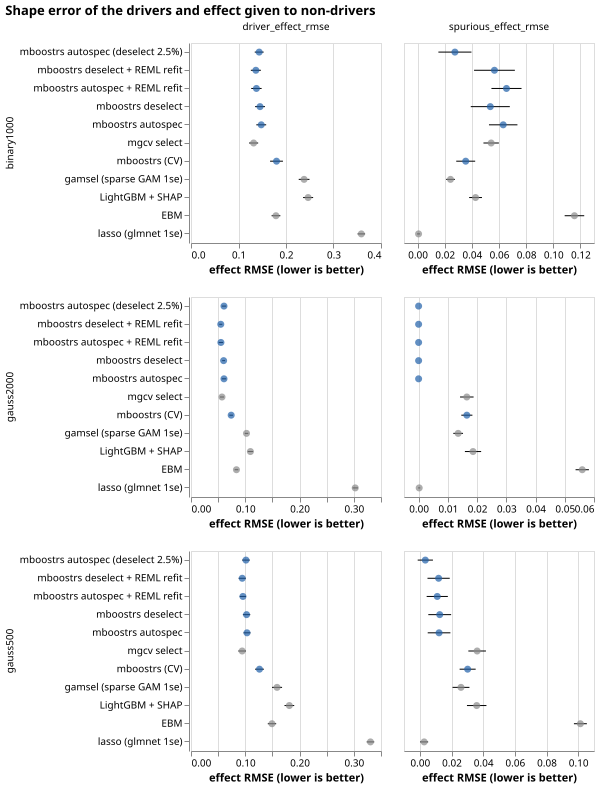

In [6]:
shapes = table.filter(pl.col("structure_error").is_not_null())
long = pl.concat([
    shapes.select("task", "method",
                  pl.lit(part).alias("part"),
                  pl.col(part).alias("error"), pl.col(f"{part} se").alias("se"))
    for part in ("driver_effect_rmse", "spurious_effect_rmse")
]).with_columns((pl.col("error") - 2 * pl.col("se")).alias("low"),
                (pl.col("error") + 2 * pl.col("se")).alias("high"),
                pl.col("method").str.starts_with("mboostrs").alias("mboostrs"))

base = alt.Chart(long).encode(
    y=alt.Y("method:N", title=None, sort=alt.EncodingSortField("error", op="mean")))
chart = (base.mark_rule().encode(x=alt.X("low:Q", title="effect RMSE (lower is better)"),
                                 x2="high:Q")
         + base.mark_point(filled=True, size=50).encode(
             x="error:Q",
             color=alt.Color("mboostrs:N", legend=None,
                             scale=alt.Scale(range=["#8a8a8a", "#1f5fa8"]))))
chart.properties(width=190, height=200).facet(
    row=alt.Row("task:N", title=None), column=alt.Column("part:N", title=None)
).resolve_scale(x="independent").properties(
    title="Shape error of the drivers and effect given to non-drivers")

The REML refit after deselection has the lowest structure error at 500
and 2,000 rows ({eval}`round(value("gauss500", "mboostrs deselect + REML refit", "structure_error"), 3)`
and {eval}`round(value("gauss2000", "mboostrs deselect + REML refit", "structure_error"), 3)`,
against {eval}`round(value("gauss500", "mgcv select", "structure_error"), 3)` and
{eval}`round(value("gauss2000", "mgcv select", "structure_error"), 3)` for mgcv).
Its driver shapes are as accurate as mgcv's, and it gives the non-drivers
exactly zero effect because they are not in the model; mgcv's `select=TRUE`
shrinks unneeded smooths towards zero but leaves small effects on some of
them. The boosted fit without deselection has shrunken driver shapes (early
stopping stops before the steeper parts of each curve are fitted) and small
effects on the noise columns it kept. EBM gives the most effect to
non-drivers ({eval}`round(value("gauss500", "EBM", "spurious_effect_rmse"), 3)`
at 500 rows): its bagged, cyclic boosting of every feature assigns each column
some shape. On the binary task the default mboostrs routes have structure
error {eval}`round(value("binary1000", "mboostrs autospec + REML refit", "structure_error"), 3)`
against mgcv's {eval}`round(value("binary1000", "mgcv select", "structure_error"), 3)`,
the difference coming from the noise columns the 1% rule keeps;
`autospec(deselect=0.025)`, which keeps fewer of them, reaches
{eval}`round(value("binary1000", "mboostrs autospec (deselect 2.5%)", "structure_error"), 3)`.

In [7]:
# Structure error and the signal RMSE on test rows, per task.
annotated(shapes.select("task", "method", "structure_error", "driver_effect_rmse",
                        "spurious_effect_rmse", "signal_rmse", "seconds")
          .sort("task", "structure_error"),
          title="Effect recovery and prediction by task",
          subtitle="Means over 20 seeds; errors in response units (link scale for the binary task); lower is better",
          group="task",
          labels={"structure_error": "structure ↓", "driver_effect_rmse": "drivers ↓",
                  "spurious_effect_rmse": "non-drivers ↓", "signal_rmse": "signal RMSE ↓",
                  "seconds": "s"},
          spanners={"Partial-effect error": ["structure_error", "driver_effect_rmse",
                                             "spurious_effect_rmse"]},
          better={"structure_error": "min", "driver_effect_rmse": "min",
                  "spurious_effect_rmse": "min", "signal_rmse": "min"},
          formats={"seconds": 1},
          notes=["structure: the shape errors of all 30 predictors combined; drivers: the six "
                 "drivers' mean error; non-drivers: the effect given to the 24 non-drivers (0 is "
                 "ideal). signal RMSE: predictions against the true mean on test rows. s: mean "
                 "seconds per fit. Bold: best within each task. Source: "
                 "bench_drivers_preexploration.json."])


GT(_tbl_data=shape: (33, 7)
┌────────────┬──────────────┬──────────────┬──────────────┬─────────────┬─────────────┬────────────┐
│ task       ┆ method       ┆ structure_er ┆ driver_effec ┆ spurious_ef ┆ signal_rmse ┆ seconds    │
│ ---        ┆ ---          ┆ ror          ┆ t_rmse       ┆ fect_rmse   ┆ ---         ┆ ---        │
│ str        ┆ str          ┆ ---          ┆ ---          ┆ ---         ┆ f64         ┆ f64        │
│            ┆              ┆ f64          ┆ f64          ┆ f64         ┆             ┆            │
╞════════════╪══════════════╪══════════════╪══════════════╪═════════════╪═════════════╪════════════╡
│ binary1000 ┆ mboostrs     ┆ 0.076549     ┆ 0.143525     ┆ 0.027516    ┆ 0.427279    ┆ 12.514779  │
│            ┆ autospec     ┆              ┆              ┆             ┆             ┆            │
│            ┆ (deselect    ┆              ┆              ┆             ┆             ┆            │
│            ┆ 2.…          ┆              ┆              ┆             ┆             ┆            │
│ binary1000 ┆ mgcv select  ┆ 0.082166     ┆ 0.131823     ┆ 0.054225    ┆ 0.432326    ┆ 236.984578 │
│ binary1000 ┆ mboostrs     ┆ 0.0881       ┆ 0.136541     ┆ 0.05665     ┆ 0.46831     ┆ 11.432418  │
│            ┆ deselect +   ┆              ┆              ┆             ┆             ┆            │
│            ┆ REML refit   ┆              ┆              ┆             ┆             ┆            │
│ binary1000 ┆ mboostrs     ┆ 0.088139     ┆ 0.145317     ┆ 0.053582    ┆ 0.469989    ┆ 2.469295   │
│            ┆ deselect     ┆              ┆              ┆             ┆             ┆            │
│ binary1000 ┆ mboostrs     ┆ 0.091538     ┆ 0.137745     ┆ 0.065512    ┆ 0.498766    ┆ 21.922791  │
│            ┆ autospec +   ┆              ┆              ┆             ┆             ┆            │
│            ┆ REML refit   ┆              ┆              ┆             ┆             ┆            │
│ …          ┆ …            ┆ …            ┆ …            ┆ …           ┆ …           ┆ …          │
│ gauss500   ┆ mboostrs     ┆ 0.066411     ┆ 0.126157     ┆ 0.030193    ┆ 0.346331    ┆ 1.706577   │
│            ┆ (CV)         ┆              ┆              ┆             ┆             ┆            │
│ gauss500   ┆ gamsel       ┆ 0.085239     ┆ 0.158509     ┆ 0.025987    ┆ 0.456056    ┆ 10.630837  │
│            ┆ (sparse GAM  ┆              ┆              ┆             ┆             ┆            │
│            ┆ 1se)         ┆              ┆              ┆             ┆             ┆            │
│ gauss500   ┆ LightGBM +   ┆ 0.091626     ┆ 0.181174     ┆ 0.035913    ┆ 0.516081    ┆ 3.002412   │
│            ┆ SHAP         ┆              ┆              ┆             ┆             ┆            │
│ gauss500   ┆ EBM          ┆ 0.114691     ┆ 0.149177     ┆ 0.101404    ┆ 0.579118    ┆ 254.245245 │
│ gauss500   ┆ lasso        ┆ 0.16301      ┆ 0.330583     ┆ 0.002723    ┆ 0.904414    ┆ 8.019157   │
│            ┆ (glmnet 1se) ┆              ┆              ┆             ┆             ┆            │
└────────────┴──────────────┴──────────────┴──────────────┴─────────────┴─────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x1126f0e30>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.row_group: 3>, column_label='task', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='structure_error', type=<ColInfoTypeEnum.default: 1>, column_label='structure ↓', column_align='right', column_width=None), ColInfo(var='driver_effect_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='drivers ↓', column_align='right', column_width=None), ColInfo(var='spurious_effect_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='non-drivers ↓', column_align='right', column_width=None), ColInfo(var='signal_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='signal RMSE ↓', column_align='right

## Automatic specification

The current autospec rows use native preliminary trees to order Gaussian
shape comparisons and to propose alternatives from marginal and partial-
dependence diagnostics. Binomial fits do not prune link-scale shapes with
response-scale diagnostics. The search still tunes each candidate, and
`deselect` removes weak retained terms subject to its validation rule.
The [pre-exploration comparison](benchmark_preexploration.ipynb) isolates
screening modes; the present benchmark compares complete library workflows.
`rec.fit(data, refit="reml")` adds smoothing-parameter estimation after selection.


## Interpretation

Prediction tuning, selection and effect estimation answer different questions.
Read the reported set against both the driver-detection rate and the number
of non-drivers retained; importance AUC alone does not select a set. Compare
shape error separately from selection, because a model can include the right
variables while shrinking their effects. Selection here describes prediction
conditional on measured columns and does not identify causes.


## Limitations

The drivers are additive; a driver that acts only through an interaction has
no main effect for a one-column screen to find (see the interaction benchmark).
The proxies are correlated 0.8 with their drivers; at higher correlation no
method can separate a driver from its proxy without more rows. The selected
set of any method here is a statement about prediction given the other
columns, not about causation: a column that is a consequence of the response,
or a common effect of a driver and the response, would be selected as readily
as a driver. Timings are single-threaded fits on one machine
(`bench["provenance"]`).